# Ovarian tumor cohort (1/4): Fig. 5a–e, Supplementary Figs. S5–S7, S8d, the VAF of the variants with φ ≥ 0.1 and Supplementary Table 1

The ovarian results are computed in this order:

1. **`04a_ovarian.ipynb`** (this notebook): the fit, the clones, the capture of the 64 variants (Fig. 5a–e, Supplementary Figs. S5–S7, S8d, the supplementary figure of the variants after S5, Supplementary Table 1).
2. `04b_ovarian_within_donor.ipynb`: capture and enrichment within each donor (Supplementary Fig. S9).
3. `04c_ovarian_chromvar.R` (motif activity), `04d_ovarian_motif.ipynb` (the motif tests, Fig. 5f–h, Supplementary Fig. S8a–c) and `04e_ovarian_motif_seurat_check.R` (the mutation-based test against Seurat).

- Data: `data/mitotrek/` (model inputs, `preprocess/ovarian/build_model_inputs.ipynb`) and the cell-type labels of the source study (`data/mitotrek/paper_supp/tableS2_ovarian_tumor_labels.csv`).
- Fit: `output/v2/ovarian_bkg/202610/11/080711` (with the decomposition of $\phi$), trained by `retrain/train_ovarian.py bkg`. The fit without the decomposition, `output/v2/ovarian_nobkg/202610/11/174848` (`retrain/train_ovarian_nobkg.py`: the same first stage, the later stages without the decomposition), is compared in section 6.
- Output: `analysis/results/ovarian/`, one PDF per panel, Supplementary Figs. S5–S7 assembled from them (Fig. 5 and Supplementary Fig. S8 in `04f_ovarian_figure5.ipynb`), and the tables below as CSV.

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os
import ast
import re

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import pearsonr, rankdata, spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors

In [3]:
RUN = '../output/v2/ovarian_bkg/202610/11/080711'
RUN_NODECOMP = '../output/v2/ovarian_nobkg/202610/11/174848'
LABELS = '../data/mitotrek/paper_supp/tableS2_ovarian_tumor_labels.csv'
OUT = '../analysis/results/ovarian'
os.makedirs(OUT, exist_ok=True)

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
S = 0.12                                # point size of the UMAP panels (108,260 cells)
RASTER = True
DIM = '#e2e1dd'                         # cells not covered (depth < 10)
den = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)


def map_vaf(xy, v, covered, title, s, vmax=None):
    # VAF of the covered cells, high values on top; cells not covered in light grey
    fig, ax = new_map()
    ax.scatter(xy[~covered, 0], xy[~covered, 1], s=s, color=DIM, linewidths=0, rasterized=RASTER)
    vmax = float(v[covered].max()) if vmax is None else vmax
    o = np.flatnonzero(covered)[np.argsort(v[covered])]
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=VAF_CMAP, vmin=0, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0, vmax), VAF_CMAP), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label('VAF')
    ax.set_title(title)
    return fig, ax

## 1. The data and the fit

In [6]:
adata_mg = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')    # X = depth, layers VAF; pi, phi, z of the fit
adata_mg

AnnData object with n_obs × n_vars = 108260 × 64
    obs: 'gsm', 'donor', 'tissue', 'clonotype_signac', 'mtDNA_depth'
    var: 'selected_in_donors', 'n_donors_selected', 'vs_position', 'vs_nucleotide', 'vs_vmr', 'vs_strand_correlation', 'vs_n_cells_conf_detected', 'vs_mean_heteroplasmy', 'vs_mean_coverage'
    uns: 'alpha', 'cohort', 'variant_selection'
    obsm: 'X_cloneVI_umap', 'pi_deleted', 'pi_sorted', 'z'
    varm: 'phi_0', 'phi_deleted', 'phi_k', 'phi_sorted', 'phi_specific'
    layers: 'VAF', 'all_mut', 'reconst_VAF'

In [7]:
D = den(adata_mg.X).astype(float)
V = den(adata_mg.layers['VAF']).astype(float)
ALT = np.rint(D * V)                                      # alternate reads
variants = np.array([str(v) for v in adata_mg.var_names])
col = {m: j for j, m in enumerate(variants)}
donor = adata_mg.obs['donor'].astype(str).to_numpy()
gsm = adata_mg.obs['gsm'].astype(str).to_numpy()
DONORS = sorted(set(donor))
pd.Series({'cells': adata_mg.n_obs, 'variants': len(variants), 'donors': len(DONORS), 'libraries': len(set(gsm))})

cells        108260
variants         64
donors            5
libraries        11
dtype: int64

### Settings of the fit

The donor is given to the encoder and the decoders as a covariate (`n_samples`). The run also records the seed and, for each stage, the epoch with the lowest validation loss (whose weights are kept) and the epoch where the stage ended. Methods: latent dimension $L = \max(10, \lfloor F^{1/4} \rfloor)$ and hidden dimension $\max(50, \lfloor F^{1/2} \rfloor)$ for $F$ input peaks.

In [8]:
params, key = {}, None
for line in open(f'{RUN}/used_parameters.txt'):            # a value can run over several lines
    m = re.match(r'^(\w+): (.*)$', line.rstrip('\n'))
    if m:
        key, params[m.group(1)] = m.group(1), m.group(2)
    else:
        params[key] += ' ' + line.strip()
mp = params['model_params']
get = lambda k: re.search(rf"'{k}': ([^,}}]+)", mp).group(1)
F = int(re.search(r'\((\d+), (\d+)\)', params['adata_shape']).group(2))
lh = ast.literal_eval(params['loss_hparams'])
fit = pd.Series({'model input (cells, peaks)': params['adata_shape'], 'K (candidate clones)': int(get('k')),
                 'latent dimension (recorded / formula)': (int(get('xz_dim')), max(10, int(F ** 0.25))),
                 'hidden dimension (recorded / formula)': (int(get('enc_z_h_dim')), max(50, int(F ** 0.5))),
                 'phi decomposition': get('use_phi_common'), 'donor covariate (n_samples)': int(get('n_samples')),
                 'regularization stage': params['use_sparse_term'], 'lambda_pi, lambda_phi': (lh['lmd_pi'], lh['lmd_phi']),
                 'validation / test fraction': (params['val_ratio'], params['test_ratio']),
                 'seed': int(params['seed']),
                 'stages (stage, best epoch, end epoch)': next(l.split(': ', 1)[1].strip() for l in open(f'{RUN}/used_parameters.txt')
                                                               if l.startswith('stages ('))}, dtype=object)
fit

model input (cells, peaks)                                                 (108260, 85859)
K (candidate clones)                                                                    20
latent dimension (recorded / formula)                                             (17, 17)
hidden dimension (recorded / formula)                                           (293, 293)
phi decomposition                                                                     True
donor covariate (n_samples)                                                              5
regularization stage                                                                  True
lambda_pi, lambda_phi                                                            (0.01, 1)
validation / test fraction                                                     (0.05, 0.1)
seed                                                                                    42
stages (stage, best epoch, end epoch)    [('train_x', 430, 630), ('train_pi', 2330, 253...

### Pruned clones and their numbers

A clone is kept if its mean $\pi$ exceeds 0.01 or its largest $\pi$ is at least 0.2 (Methods). The clones are numbered by their index among the 20 candidates, as in the paper (here the kept ones are 0–15 and 17).

In [9]:
pi_all = np.asarray(adata_mg.obsm['pi_sorted'], dtype=float)
kept = np.flatnonzero((pi_all.mean(0) > 0.01) | (pi_all.max(0) >= 0.2))
pi = np.asarray(adata_mg.obsm['pi_deleted'], dtype=float)          # cells x kept clones
phi = np.asarray(adata_mg.varm['phi_deleted'], dtype=float)        # variants x kept clones
assert np.allclose(pi, pi_all[:, kept]) and np.allclose(phi, np.asarray(adata_mg.varm['phi_sorted'], float)[:, kept])
LABEL = {i: int(k) for i, k in enumerate(kept)}                  # column of pi_deleted -> clone number
pd.DataFrame({'mean pi': pi_all.mean(0), 'max pi': pi_all.max(0), 'kept': np.isin(np.arange(pi_all.shape[1]), kept)}).round(4)

,mean pi,max pi,kept
0,0.2332,0.9874,True
1,0.1837,0.7108,True
2,0.1620,0.5207,True
3,0.1512,0.7450,True
4,0.0419,0.9927,True
5,0.0407,0.8513,True
6,0.0309,0.5010,True
7,0.0255,0.6276,True
8,0.0242,0.6481,True
9,0.0218,0.5110,True


## 2. The clones

For each kept clone: the donor holding most of its probability and that share; its variant, the one where its allele frequency most exceeds the shared component ($\phi_{km} - \phi^{(\text{common})}_m$); and every variant it carries at $\phi \geq 0.1$.

In [10]:
phi0 = np.asarray(adata_mg.varm['phi_0'], dtype=float).mean(1)    # shared component (stored tiled over clones)
excess = phi - phi0[:, None]
K12 = LABEL[int(excess[col['12879T>C']].argmax())]   # the clone of 12879T>C (Clone 11; the rule of 04d)
W = pd.DataFrame(pi, index=donor).groupby(level=0).sum()
clones = pd.DataFrame({'clone': [LABEL[i] for i in range(pi.shape[1])],
                       'donor': W.idxmax(0).to_numpy(), 'donor share': (W.max(0) / W.sum(0)).to_numpy(),
                       'pi mass': pi.sum(0),
                       'variant': variants[excess.argmax(0)], 'excess over shared': excess.max(0),
                       'variants with phi >= 0.1': [', '.join(f'{variants[j]} ({phi[j, i]:.2f})' for j in np.argsort(-phi[:, i])
                                                             if phi[j, i] >= 0.1) for i in range(pi.shape[1])]})
clones.to_csv(f'{OUT}/clones.csv', index=False)
clones.round(3)

,clone,donor,donor share,pi mass,variant,excess over shared,variants with phi >= 0.1
0,0,SU-O-004,0.806,25248.287,3109T>C,0.013,310T>C (0.23)
1,1,SU-O-005,0.769,19888.804,3109T>C,0.026,310T>C (0.74)
2,2,SU-O-005,0.693,17536.652,310T>C,0.001,310T>C (0.74)
3,3,SU-O-002,0.733,16369.809,515A>G,0.198,"310T>C (0.78), 515A>G (0.20)"
4,4,SU-O-004,1.000,4534.617,7738T>C,0.911,"7738T>C (0.91), 310T>C (0.22)"
5,5,SU-O-004,1.000,4401.384,7738T>C,0.996,"7738T>C (1.00), 12652T>C (0.39), 310T>C (0.22)"
6,6,SU-O-004,0.991,3341.583,12071T>C,0.381,"12071T>C (0.38), 310T>C (0.19), 5358A>G (0.18)..."
7,7,SU-O-005,0.967,2756.452,11192G>A,0.108,"310T>C (0.47), 11192G>A (0.11)"
8,8,SU-O-002,0.443,2619.280,709G>A,0.499,"310T>C (0.58), 709G>A (0.50)"
9,9,SU-O-004,1.000,2360.756,7738T>C,0.994,"7738T>C (0.99), 9554G>A (0.25), 310T>C (0.21),..."


In [11]:
pd.Series({'clones with > 90% of their probability in one donor': int((clones['donor share'] > 0.9).sum()),
           'clones whose variant exceeds the shared component by <= 0.02': ', '.join(
               str(c) for c in clones.loc[clones['excess over shared'] <= 0.02, 'clone'])})

clones with > 90% of their probability in one donor               10
clones whose variant exceeds the shared component by <= 0.02    0, 2
dtype: object

The lineage of donor SU-O-004: three clones carry 7738T>C and are told apart by 12652T>C and 9554G>A.

In [12]:
c_of = {LABEL[i]: i for i in LABEL}
LIN = [LABEL[i] for i in np.flatnonzero(phi[col['7738T>C']] > 0.5)]          # the clones carrying 7738T>C (Clones 4, 5 and 9)
K12652, K9554 = (LABEL[int(phi[col[m]].argmax())] for m in ('12652T>C', '9554G>A'))   # Clones 5 and 9
lineage = pd.DataFrame({m: [phi[col[m], c_of[k]] for k in LIN] for m in ('7738T>C', '12652T>C', '9554G>A')},
                       index=[f'Clone {k}' for k in LIN]).round(3)
in4 = donor == 'SU-O-004'
lineage, round(pearsonr(pi[in4, c_of[K12652]], pi[in4, c_of[K9554]])[0], 3)

(         7738T>C  12652T>C  9554G>A
 Clone 4    0.911     0.054    0.016
 Clone 5    0.996     0.386    0.044
 Clone 9    0.994     0.167    0.247,
 0.914)

## 3. Supplementary Fig. S6: the decomposition of the allele frequency

$\phi_k = \alpha_k \phi^{(\text{common})} + (1 - \alpha_k) \phi^{(\text{specific})}_k$. The shared component should take up variants carried by almost every cell.

In [13]:
alpha = np.asarray(adata_mg.uns['alpha'], dtype=float)[0]           # stored tiled over variants
phik = np.asarray(adata_mg.varm['phi_k'], dtype=float)[:, kept]
assert np.allclose(phi, alpha[kept] * phi0[:, None] + (1 - alpha[kept]) * phik, atol=1e-5)
covered_all = D >= 10
mutant_share = ((V >= 0.10) & covered_all & (ALT >= 3)).sum(0) / covered_all.sum(0)
pd.DataFrame({'phi_common': phi0, 'share of covered cells mutant': mutant_share}, index=variants
             ).sort_values('phi_common', ascending=False).head(5).round(3), int((phi0 < 0.01).sum())

(          phi_common  share of covered cells mutant
 310T>C         0.736                          0.914
 4837C>A        0.004                          0.002
 13108T>A       0.002                          0.001
 6374T>C        0.001                          0.000
 16387A>G       0.001                          0.000,
 63)

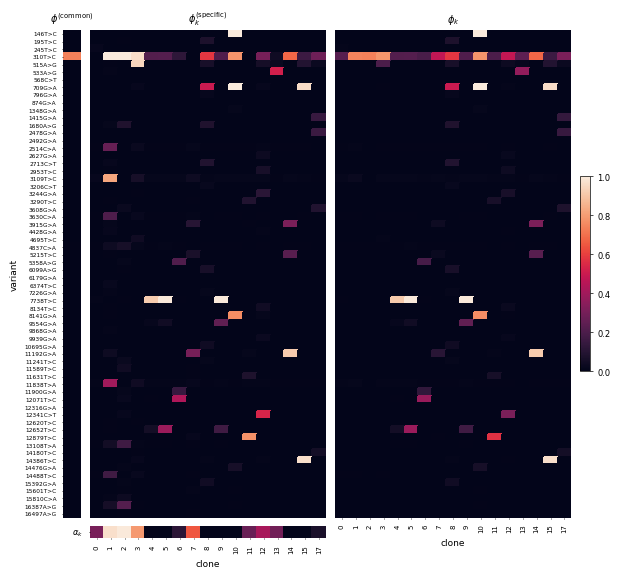

In [14]:
labels_k = [str(LABEL[i]) for i in range(pi.shape[1])]
fig = plt.figure(figsize=(6.8, 6.6))
gs = fig.add_gridspec(2, 4, width_ratios=[1.3, len(kept), len(kept), 0.7], height_ratios=[len(variants), 1.6],
                      wspace=0.07, hspace=0.035)
kw = dict(vmin=0, vmax=1, cbar=False, linewidths=0.3, linecolor='face')
ax0 = fig.add_subplot(gs[0, 0])
sns.heatmap(phi0[:, None], ax=ax0, yticklabels=list(variants), xticklabels=False, **kw)
ax0.set_title(r'$\phi^{(\mathrm{common})}$')
ax0.set_ylabel('variant')
ax1 = fig.add_subplot(gs[0, 1])
sns.heatmap(phik, ax=ax1, yticklabels=False, xticklabels=False, **kw)
ax1.set_title(r'$\phi^{(\mathrm{specific})}_k$')
axa = fig.add_subplot(gs[1, 1])
sns.heatmap(alpha[kept][None, :], ax=axa, yticklabels=[r'$\alpha_k$'], xticklabels=labels_k, **kw)
axa.set_xlabel('clone')
ax2 = fig.add_subplot(gs[0, 2])
sns.heatmap(phi, ax=ax2, yticklabels=False, xticklabels=labels_k, **kw)
ax2.set_title(r'$\phi_k$')
ax2.set_xlabel('clone')
for a in (ax0, ax1, axa, ax2):
    a.tick_params(axis='y', labelsize=4.2, length=1, rotation=0)
    a.tick_params(axis='x', labelsize=5, length=1, rotation=90)
axa.tick_params(axis='y', labelsize=6)
cax_box = fig.add_subplot(gs[0, 3])
cax_box.axis('off')
fig.colorbar(ax2.collections[0], cax=cax_box.inset_axes([0, 0.3, 1, 0.4]))
save(fig, 'supfig6_phi_decomposition')

## 4. Fig. 5a–c, Supplementary Figs. S5 and S7: the cohort and the clones on the CloneVI UMAP

The UMAP of the cell state $z$ inferred by CloneVI (the donor is a covariate of the encoder).

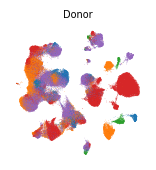

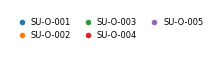

In [15]:
xy = adata_mg.obsm['X_cloneVI_umap']
donor_col = dict(zip(DONORS, plt.get_cmap('tab10')(np.arange(len(DONORS)))))
fig, ax = map_groups(xy, donor, donor_col, 'Donor', S, legend=False)
save(fig, 'fig5a_donor')
fig = legend_panel(donor_col, {d: d for d in DONORS}, ncol=3)
save(fig, 'fig5a_legend')

Cell types of the source study, grouped into six classes for display (Methods); cells of the libraries without labels in light grey.

In [16]:
lab = pd.read_csv(LABELS, index_col=0).reindex(adata_mg.obs_names)
GROUPS = {'tumor': (['tumor'], '#8a6fae'), 'stromal': (['fibroblast', 'endothelial'], '#c0a14a'),
          'CD8+ T': (['cd8+ t'], '#1f6f55'), 'other T/NK': (['cd4+ t', 'treg', 'nk_ilc', 'tnk_other'], '#9ccf6e'),
          'myeloid': (['dc', 'mono', 'mac'], '#d9a07a'), 'B/plasma': (['b', 'plasma'], '#b7879a')}
lv1 = lab['cell_type_lv1'].to_numpy()
group = np.full(len(lv1), 'no label', dtype=object)
for g, (members, _) in GROUPS.items():
    group[np.isin(lv1, members)] = g
group_col = {g: c for g, (_, c) in GROUPS.items()} | {'no label': DIM}
pd.Series({'labelled cells': int(pd.notna(lv1).sum()), 'libraries with labels': len(set(gsm[pd.notna(lv1)]))}), \
    pd.Series(group).value_counts()

(labelled cells           45678
 libraries with labels        7
 dtype: int64,
 no label      62582
 tumor         15282
 other T/NK     7563
 myeloid        7553
 CD8+ T         7522
 B/plasma       5051
 stromal        2707
 Name: count, dtype: int64)

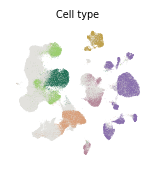

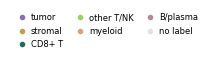

In [17]:
fig, ax = map_groups(xy, group, group_col, 'Cell type', S, legend=False)
save(fig, 'fig5b_celltype')
fig = legend_panel(group_col, {g: g for g in group_col}, ncol=3)
save(fig, 'fig5b_legend')
pd.DataFrame({'donor': donor, 'cell type': group}, index=adata_mg.obs_names).to_csv(f'{OUT}/fig5_cells.csv')   # for Fig. 5 (04f)

Every clone: its $\pi$ (Supplementary Fig. S5; Fig. 5c shows Clone 11, the clone of 12879T>C; Supplementary Fig. S7 Clones 10, 15, 4, 5 and 9) and the VAF of its variant (cells with depth below 10 in grey). Colour scales per panel, from 0 to the largest value.

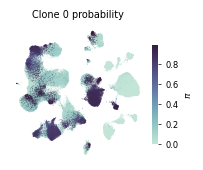

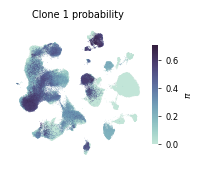

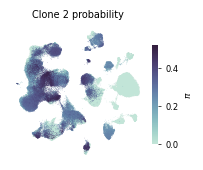

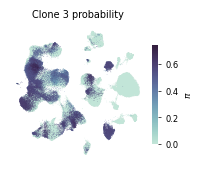

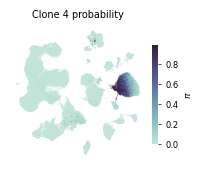

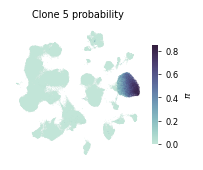

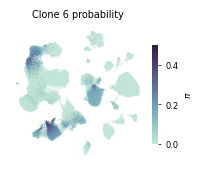

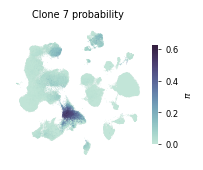

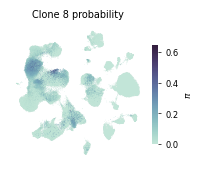

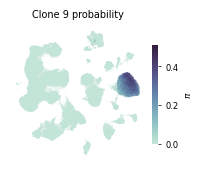

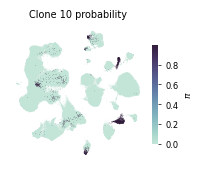

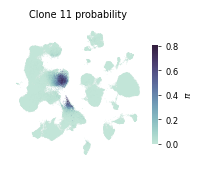

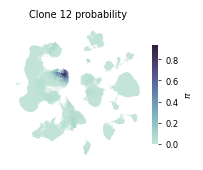

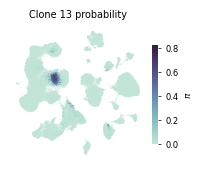

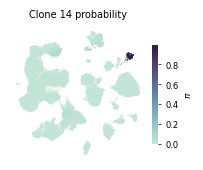

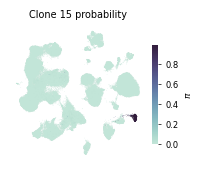

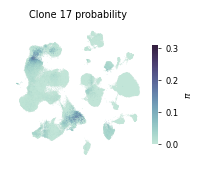

In [18]:
for i in range(pi.shape[1]):
    fig, ax = map_values(xy, pi[:, i], PI_CMAP, f'Clone {LABEL[i]} probability', r'$\pi$', S)
    save(fig, f'pi_clone{LABEL[i]}')

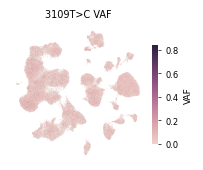

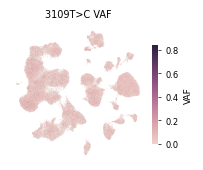

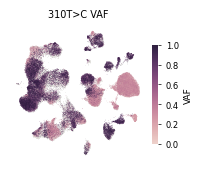

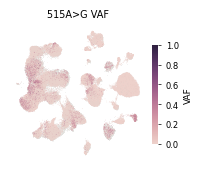

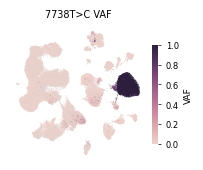

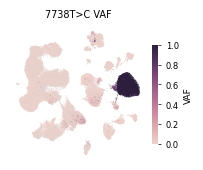

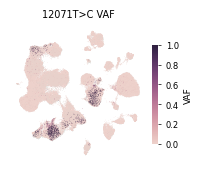

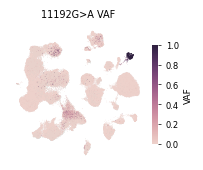

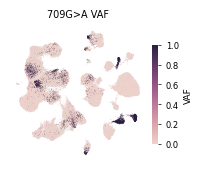

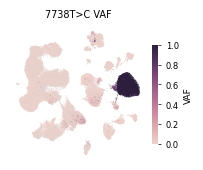

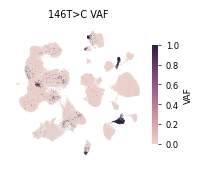

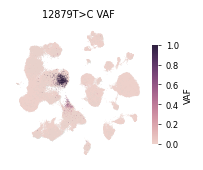

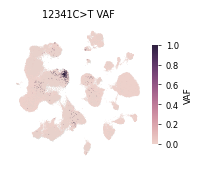

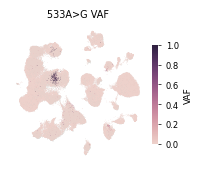

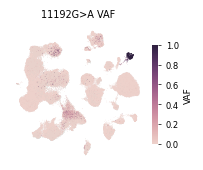

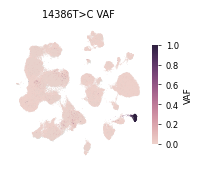

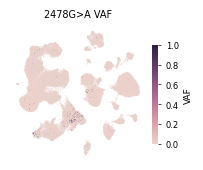

In [19]:
for i in range(pi.shape[1]):
    j = int(excess[:, i].argmax())
    fig, ax = map_vaf(xy, V[:, j], D[:, j] >= 10, f'{variants[j]} VAF', S)            # Clone and phi: the table of section 2
    save(fig, f'vaf_clone{LABEL[i]}_{variants[j].replace(">", "_")}')

### Supplementary Fig. S7: five clones with the variants that tell them apart

Upper row: $\pi$ of the clone of 146T>C and of the clone of 14386T>C (both also carry 709G>A, in different donors), and of the three clones carrying 7738T>C (the lineage of SU-O-004), with the allele frequencies $\phi$ of the variants named. Lower row: the VAF of 709G>A, 14386T>C, 7738T>C, 12652T>C and 9554G>A.

,Clone 10,Clone 15,Clone 4,Clone 5,Clone 9
709G>A,1.00,0.96,NaN,NaN,NaN
146T>C,1.00,NaN,NaN,NaN,NaN
8141G>A,0.76,NaN,NaN,NaN,NaN
14386T>C,NaN,0.97,NaN,NaN,NaN
7738T>C,NaN,NaN,0.91,1.00,0.99
12652T>C,NaN,NaN,0.05,0.39,0.17
9554G>A,NaN,NaN,0.02,0.04,0.25


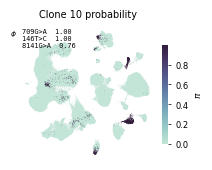

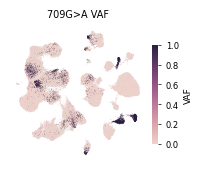

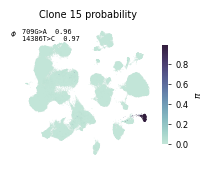

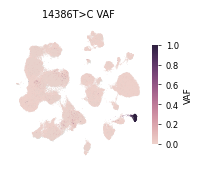

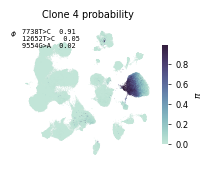

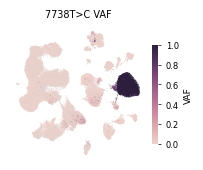

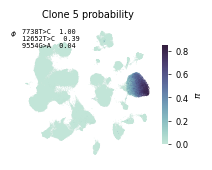

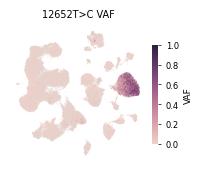

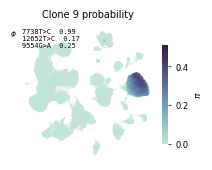

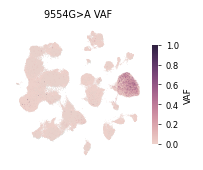

In [20]:
K10, K15 = (LABEL[int(phi[col[m]].argmax())] for m in ('146T>C', '14386T>C'))   # Clones 10 and 15
K7738 = [k for k in LIN if k not in (K12652, K9554)][0]                          # Clone 4
S7 = [(K10, ['709G>A', '146T>C', '8141G>A'], '709G>A'), (K15, ['709G>A', '14386T>C'], '14386T>C'),
      (K7738, ['7738T>C', '12652T>C', '9554G>A'], '7738T>C'), (K12652, ['7738T>C', '12652T>C', '9554G>A'], '12652T>C'),
      (K9554, ['7738T>C', '12652T>C', '9554G>A'], '9554G>A')]
for k, named, m in S7:
    i = c_of[k]
    fig, ax = map_values(xy, pi[:, i], PI_CMAP, f'Clone {k} probability', r'$\pi$', S)
    ax.text(0.02, 0.98, '\n'.join(f'{v}  {phi[col[v], i]:.2f}' for v in named), transform=ax.transAxes, va='top', ha='left',
            fontsize=5, family='monospace')
    ax.text(-0.02, 0.98, r'$\phi$', transform=ax.transAxes, va='top', ha='right', fontsize=5.5)
    save(fig, f'supfig7_pi_clone{k}')
    fig, ax = map_vaf(xy, V[:, col[m]], D[:, col[m]] >= 10, f'{m} VAF', S)
    save(fig, f'supfig7_vaf_{m.replace(">", "_")}')
pd.DataFrame({f'Clone {k}': {v: round(phi[col[v], c_of[k]], 2) for v in named} for k, named, m in S7})

## 5. Fig. 5d: the allele frequencies of the variants carried at $\phi \geq 0.1$

Rows: the variants with $\phi \geq 0.1$ in some clone, ordered by the clone carrying them; 310T>C, carried in every donor, at the bottom. Columns: clones ordered by donor (white lines between donors) and by probability mass. The strip on the left gives the donor composition of each variant's mutant cells (donors with less than 2% of them not drawn). Outlined: $\phi$ at least 0.8 times the mean VAF of the variant's mutant cells.

515A>G also has $\phi \geq 0.1$ but is not drawn: it is called only in SU-O-001 and SU-O-002, the two donors where its position is covered in far fewer cells than in the others and than the neighbouring positions, and no cell reaches VAF 0.9 — the substitution does not correspond to a population of cells. (It stays among the 64 variants of every analysis.)

In [21]:
j515 = col['515A>G']
cov_by_donor = pd.DataFrame({d: [covered_all[donor == d, j].mean() for j in (col['515A>G'], col['533A>G'])] for d in DONORS},
                            index=['515A>G covered', '533A>G covered (neighbour)']).round(2)
cov_by_donor, int((V[covered_all[:, j515], j515] >= 0.9).sum())

(                            SU-O-001  SU-O-002  SU-O-003  SU-O-004  SU-O-005
 515A>G covered                  0.34      0.17      0.95      0.84      0.81
 533A>G covered (neighbour)      0.92      0.79      0.95      0.85      0.81,
 2)

In [22]:
mutant = (V >= 0.10) & covered_all & (ALT >= 3)
rows5d = [j for j in np.flatnonzero(phi.max(1) >= 0.1) if variants[j] != '515A>G']
cl = clones.assign(i=np.arange(len(clones)))
cl['rank'] = cl['donor'].map({d: n for n, d in enumerate(DONORS)})
cl = cl.sort_values(['rank', 'pi mass'], ascending=[True, False])
cpos = {i: n for n, i in enumerate(cl['i'])}
var5d = pd.DataFrame({'j': rows5d, 'variant': variants[rows5d], 'clone_i': phi[rows5d].argmax(1), 'phi_max': phi[rows5d].max(1),
                      'mutant VAF': [V[mutant[:, j], j].mean() for j in rows5d], 'cross': [variants[j] == '310T>C' for j in rows5d]})
var5d['cpos'] = var5d['clone_i'].map(cpos)
var5d = var5d.sort_values(['cross', 'cpos', 'phi_max'], ascending=[True, True, False])
share = pd.DataFrame([pd.Series(donor[mutant[:, j]]).value_counts(normalize=True).reindex(DONORS, fill_value=0) for j in var5d['j']])
share[share < 0.02] = 0
share = share.div(share.sum(1), axis=0)
M = phi[np.ix_(var5d['j'], cl['i'])]
len(var5d), var5d[['variant', 'phi_max', 'mutant VAF']].round(3).to_string(index=False)

(19,
 ' variant  phi_max  mutant VAF\n12341C>T    0.311       0.882\n14386T>C    0.966       0.831\n  533A>G    0.367       0.684\n 2478G>A    0.145       0.677\n 1415G>A    0.138       0.698\n  146T>C    0.999       0.958\n  709G>A    0.999       0.899\n 8141G>A    0.765       0.949\n 7738T>C    0.996       0.945\n12652T>C    0.386       0.347\n12071T>C    0.381       0.785\n 5358A>G    0.184       0.742\n11900G>A    0.131       0.705\n 9554G>A    0.247       0.253\n12879T>C    0.570       0.787\n11192G>A    0.917       0.634\n 3915G>A    0.316       0.409\n 5215T>C    0.228       0.437\n  310T>C    0.784       0.538')

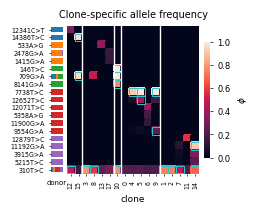

In [23]:
nv, nk = M.shape
fig = plt.figure(figsize=(2.6, 2.9))
ax = fig.add_axes([0.22, 0.12, 0.62, 0.8])
sns.heatmap(M, ax=ax, vmin=0, vmax=1, square=True, linewidths=0.3, linecolor='face', xticklabels=list(cl['clone']),
            yticklabels=False, cbar_kws={'label': r'$\phi$', 'shrink': 0.5, 'pad': 0.03})
for b in np.flatnonzero(cl['donor'].to_numpy()[1:] != cl['donor'].to_numpy()[:-1]) + 1:
    ax.axvline(b, color='white', lw=1.0)
for r_, o in enumerate(var5d['mutant VAF']):
    for k in range(nk):
        if M[r_, k] >= 0.8 * o:
            ax.add_patch(Rectangle((k, r_), 1, 1, fill=False, edgecolor='#2ec4d6', lw=0.7))
ax.set_xlabel('clone')
ax.tick_params(axis='x', labelsize=4.5, length=1.5, rotation=90)
ax.set_title('Clone-specific allele frequency')
fig.canvas.draw()                                          # square cells: the axes box is final only after drawing
pos = ax.get_position()
axd = fig.add_axes([pos.x0 - 0.06, pos.y0, 0.045, pos.height])
left = np.zeros(nv)
for d in DONORS:
    axd.barh(np.arange(nv) + 0.5, share[d].to_numpy(), left=left, height=0.72, color=donor_col[d], edgecolor='none')
    left += share[d].to_numpy()
axd.set_xlim(0, 1); axd.set_ylim(nv, 0)
axd.set_yticks(np.arange(nv) + 0.5)
axd.set_yticklabels(var5d['variant'], fontsize=4.5)
axd.set_xticks([])
axd.set_xlabel('donor', fontsize=5)
axd.tick_params(length=1.5)
for s_ in axd.spines.values():
    s_.set_visible(False)
save(fig, 'fig5d_phi')
# the table of the panel, for Fig. 5 (04f): phi of the rows and columns in this order, and per row the donors of the
# mutant cells and their mean VAF (the boxes)
pd.DataFrame(M, index=var5d['variant'].to_numpy(), columns=cl['clone'].to_numpy()).to_csv(f'{OUT}/fig5d_phi.csv')
share.set_axis(var5d['variant'].to_numpy()).assign(**{'mutant VAF': var5d['mutant VAF'].to_numpy()}).to_csv(f'{OUT}/fig5d_rows.csv')

## 6. Fig. 5e: which mutant-cell populations CloneVI captures

Definitions as for the MAESTER data (Methods): covered, depth at least 10; mutant, VAF at least 0.10 with at least three alternate reads; variants with at least 15 mutant and 15 non-mutant cells. Enrichment from a 30-nearest-neighbor graph of all 108,260 cells on standardized $z$, against 200 permutations of the mutant labels among the covered cells; capture, the AUC of the reconstructed VAF from the kept clones.

In [24]:
def knn(z):
    zs = (z - z.mean(0)) / np.maximum(z.std(0), 1e-9)
    return NearestNeighbors(n_neighbors=31).fit(zs).kneighbors(zs, return_distance=False)[:, 1:]


def measure(nn, P, phi_k, min_alt, n_perm=200):
    rng = np.random.default_rng(0)
    rows = []
    for j in range(D.shape[1]):
        cov = D[:, j] >= 10
        mut = (V[:, j] >= 0.10) & cov & (ALT[:, j] >= min_alt)
        if mut.sum() < 15 or (cov & ~mut).sum() < 15:
            continue
        car, pool = np.flatnonzero(mut), np.flatnonzero(cov)
        purity = mut[nn[car]].mean()
        null = np.empty(n_perm)
        for b in range(n_perm):
            perm = np.zeros(len(mut), bool)
            perm[rng.choice(pool, len(car), replace=False)] = True
            null[b] = perm[nn[np.flatnonzero(perm)]].mean()
        top = pd.Series(donor[car]).value_counts()
        rows.append(dict(variant=variants[j], n_mutant=int(mut.sum()), prevalence=float(np.log10(mut.sum())),
                         heteroplasmy=float(V[car, j].mean()), purity=float(purity), null_purity=float(null.mean()),
                         enrichment=float((purity - null.mean()) / max(1 - null.mean(), 1e-12)),
                         auc=float(roc_auc_score(mut[cov], P[cov, j])), phi_max=float(phi_k[j].max()),
                         top_donor=str(top.index[0]), top_donor_share=float(top.iloc[0] / len(car))))
    return pd.DataFrame(rows).set_index('variant')


nn = knn(np.asarray(adata_mg.obsm['z']))
recon = (np.asarray(adata_mg.obsm['pi_deleted']) @ np.asarray(adata_mg.varm['phi_deleted']).T).astype(float)  # float32 product, as stored
cap = measure(nn, recon, np.asarray(adata_mg.varm['phi_deleted']), min_alt=3)
cap.to_csv(f'{OUT}/fig5e_capture.csv')
len(cap)

64

In [25]:
cap.sort_values('enrichment', ascending=False).round(3)

,n_mutant,prevalence,heteroplasmy,purity,null_purity,enrichment,auc,phi_max,top_donor,top_donor_share
variant,,,,,,,,,,
7738T>C,11196,4.049,0.945,0.936,0.112,0.928,0.999,0.996,SU-O-004,1.000
8141G>A,1266,3.102,0.949,0.928,0.012,0.927,0.991,0.765,SU-O-003,0.978
14386T>C,942,2.974,0.831,0.785,0.009,0.783,0.989,0.966,SU-O-001,0.987
146T>C,2044,3.310,0.958,0.631,0.022,0.623,0.959,0.999,SU-O-003,0.891
12652T>C,6347,3.803,0.347,0.646,0.064,0.622,0.986,0.386,SU-O-004,1.000
...,...,...,...,...,...,...,...,...,...,...
6374T>C,18,1.255,0.292,0.000,0.000,-0.000,0.319,0.002,SU-O-005,0.444
11838T>A,266,2.425,0.143,0.002,0.003,-0.000,0.505,0.013,SU-O-004,0.335
4837C>A,150,2.176,0.153,0.001,0.002,-0.000,0.536,0.009,SU-O-004,0.393


Spearman correlation of each property with the AUC, and the partial Spearman correlation adjusted for the other two (Pearson correlation of the rank residuals).

In [26]:
PROPS = ['prevalence', 'heteroplasmy', 'enrichment']


def partial_spearman(d, x, y, covs):
    C = np.column_stack([np.ones(len(d))] + [rankdata(d[c]) for c in covs])
    resid = lambda v: v - C @ np.linalg.lstsq(C, v, rcond=None)[0]
    return pearsonr(resid(rankdata(d[x])), resid(rankdata(d[y])))[0]


def correlations(d):
    return pd.DataFrame({'rho': [spearmanr(d[x], d['auc'])[0] for x in PROPS],
                         'partial rho': [partial_spearman(d, x, 'auc', [c for c in PROPS if c != x]) for x in PROPS]},
                        index=PROPS)


corr = correlations(cap)
corr.to_csv(f'{OUT}/fig5e_correlations.csv')
corr.round(3), cap[['prevalence', 'heteroplasmy']].corrwith(cap['enrichment'], method='spearman').round(3)

(                rho  partial rho
 prevalence    0.447       -0.251
 heteroplasmy  0.396       -0.144
 enrichment    0.806        0.750,
 prevalence      0.686
 heteroplasmy    0.570
 dtype: float64)

3109T>C, mutant in many cells at low VAF:

In [27]:
j3109 = col['3109T>C']
m3109 = mutant[:, j3109]
pd.Series({'mutant cells': int(m3109.sum()), 'donors': len(set(donor[m3109])), 'cells with VAF > 0.5': int((V[m3109, j3109] > 0.5).sum()),
           'enrichment': round(cap.loc['3109T>C', 'enrichment'], 4), 'AUC': round(cap.loc['3109T>C', 'auc'], 3)})

mutant cells            902.0000
donors                    5.0000
cells with VAF > 0.5      1.0000
enrichment                0.0023
AUC                       0.5340
dtype: float64

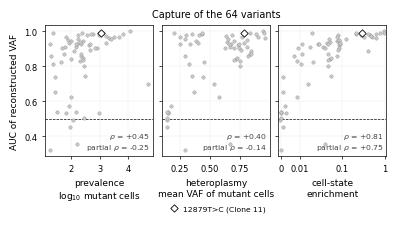

In [28]:
XLAB = {'prevalence': 'prevalence\nlog$_{10}$ mutant cells', 'heteroplasmy': 'heteroplasmy\nmean VAF of mutant cells',
        'enrichment': 'cell-state\nenrichment'}
fig, axes = plt.subplots(1, 3, figsize=(4.4, 1.7), sharey=True, gridspec_kw={'wspace': 0.08})
for ax, x in zip(axes, PROPS):
    rest = cap.drop(index='12879T>C')
    ax.scatter(rest[x], rest['auc'], s=6, c='#c8c8c8', edgecolor='#8a8a8a', lw=0.25, zorder=2)
    ax.scatter(cap.loc['12879T>C', x], cap.loc['12879T>C', 'auc'], marker='D', s=14, c='white', edgecolor='k', lw=0.6,
               zorder=4, label=f'12879T>C (Clone {K12})')
    ax.axhline(0.5, color='k', lw=0.5, ls='--', zorder=1)
    if x == 'enrichment':
        ax.set_xscale('symlog', linthresh=0.01, linscale=0.4)
        ax.set_xticks([0, 0.01, 0.1, 1]); ax.set_xticklabels(['0', '0.01', '0.1', '1'])
        ax.set_xlim(-0.0015, 1.08)
    ax.set_xlabel(XLAB[x])
    ax.grid(alpha=0.25, lw=0.3)
    ax.text(0.97, 0.03, f'$\\rho$ = {corr.loc[x, "rho"]:+.2f}\npartial $\\rho$ = {corr.loc[x, "partial rho"]:+.2f}',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=5.5, color='#444')
axes[0].set_ylabel('AUC of reconstructed VAF')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=5.5, handletextpad=0.2)
axes[1].set_title(f'Capture of the {len(cap)} variants')
save(fig, 'fig5e_capture')

### Sensitivity analysis and the fit without the decomposition (Methods; Supplementary Fig. S6 legend)

Without the requirement of three alternate reads; and the same analysis on the fit without the decomposition of $\phi$ (its own $z$, neighbor graph and reconstruction).

In [29]:
cap_alt1 = measure(nn, recon, np.asarray(adata_mg.varm['phi_deleted']), min_alt=1)
cap_alt1.to_csv(f'{OUT}/capture_without_alt3.csv')
corr_alt1 = correlations(cap_alt1)
corr_alt1.round(3)

,rho,partial rho
prevalence,0.368,0.095
heteroplasmy,0.607,0.150
enrichment,0.889,0.797


In [30]:
nodecomp = sc.read_h5ad(f'{RUN_NODECOMP}/cloneVI_result.h5ad')
assert (nodecomp.obs_names == adata_mg.obs_names).all() and np.array_equal(den(nodecomp.X), den(adata_mg.X))
recon_nd = (np.asarray(nodecomp.obsm['pi_deleted']) @ np.asarray(nodecomp.varm['phi_deleted']).T).astype(float)
cap_nd = measure(knn(np.asarray(nodecomp.obsm['z'])), recon_nd, np.asarray(nodecomp.varm['phi_deleted']), min_alt=3)
cap_nd.to_csv(f'{OUT}/capture_fit_without_decomposition.csv')
corr_nd = correlations(cap_nd)
pd.concat({'with decomposition': corr, 'without decomposition': corr_nd}, axis=1).round(3)

with decomposition             without decomposition            
                            rho partial rho                   rho partial rho
prevalence                0.447      -0.251                 0.540      -0.075
heteroplasmy              0.396      -0.144                 0.480       0.008
enrichment                0.806       0.750                 0.833       0.711

## 7. Supplementary Table 1 and Supplementary Fig. S8d

One row per variant: the values of Fig. 5e, the donor holding most mutant cells, and the clone with the largest $\phi$ among all 20 candidates (whether it was kept, and its probability mass).

In [31]:
phi_all = pd.DataFrame(np.asarray(adata_mg.varm['phi_sorted']), index=variants)
k_all = phi_all.to_numpy().argmax(1)
T1 = pd.DataFrame({'variant': variants, 'n_mutant_cells': cap.loc[variants, 'n_mutant'].to_numpy(),
                   'mean_VAF_mutant': cap.loc[variants, 'heteroplasmy'].round(3).to_numpy(),
                   'enrichment': cap.loc[variants, 'enrichment'].round(4).to_numpy(),
                   'AUC': cap.loc[variants, 'auc'].round(3).to_numpy(), 'top_donor': cap.loc[variants, 'top_donor'].to_numpy(),
                   'top_donor_share': cap.loc[variants, 'top_donor_share'].round(3).to_numpy(), 'clone': k_all,
                   'phi': phi_all.to_numpy().max(1).round(3), 'clone_retained': np.isin(k_all, kept),
                   'clone_pi_mass': pi_all.sum(0)[k_all].round(1)}).sort_values('AUC', ascending=False)
T1.to_csv(f'{OUT}/supptable1_variants.csv', index=False)
T1

,variant,n_mutant_cells,mean_VAF_mutant,enrichment,AUC,top_donor,top_donor_share,clone,phi,clone_retained,clone_pi_mass
35,7738T>C,11196,0.945,0.9284,0.999,SU-O-004,1.000,5,0.996,True,4401.4
61,15810C>A,22,0.203,0.0195,0.992,SU-O-003,1.000,10,0.003,True,2076.0
53,12879T>C,1055,0.787,0.2839,0.991,SU-O-005,0.997,11,0.570,True,1516.7
37,8141G>A,1266,0.949,0.9275,0.991,SU-O-003,0.978,10,0.765,True,2076.0
56,14386T>C,942,0.831,0.7828,0.989,SU-O-001,0.987,15,0.966,True,780.1
...,...,...,...,...,...,...,...,...,...,...,...
46,11838T>A,266,0.143,-0.0002,0.505,SU-O-004,0.335,1,0.013,True,19888.8
15,2514C>A,116,0.143,-0.0006,0.495,SU-O-005,0.362,1,0.008,True,19888.8
24,3630C>A,86,0.142,0.0011,0.451,SU-O-004,0.314,1,0.006,True,19888.8
39,9868G>A,157,0.665,0.0377,0.358,SU-O-002,0.764,16,0.076,False,711.4


The 902 mutant cells of 3109T>C on the cohort UMAP, with the covered non-mutant cells in grey (Supplementary Fig. S8d):

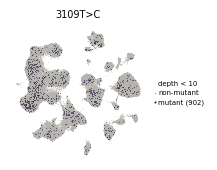

In [32]:
cov3109 = covered_all[:, j3109]
grp = np.where(~cov3109, 'not covered', np.where(m3109, 'mutant', 'non-mutant'))
fig, ax = new_map()
for g_, c_, s_, lab_ in [('not covered', DIM, S, 'depth < 10'), ('non-mutant', '#b5b4ae', S, 'non-mutant'),
                         ('mutant', VAF_CMAP(1.0), 2 * S, f'mutant ({int(m3109.sum())})')]:
    m_ = grp == g_
    ax.scatter(xy[m_, 0], xy[m_, 1], s=s_, color=c_, linewidths=0, rasterized=RASTER, label=lab_)
ax.set_aspect('equal', adjustable='datalim')
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, handletextpad=0.1, markerscale=3, handlelength=0.8,
          fontsize=5)
ax.set_title('3109T>C')
save(fig, 'supfig8d_3109')

## 8. The numbers in the paper

The numbers of the ovarian analysis quoted in the paper that this notebook computes, next to the computed values; within-donor results are in `04b`, the motif tests in `04d`. `where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [33]:
f2 = lambda x: f'{x:+.2f}'
K10, K15 = (LABEL[int(phi[col[m]].argmax())] for m in ('146T>C', '14386T>C'))   # Clones 10 and 15
c10, c15 = clones.set_index('clone').loc[K10], clones.set_index('clone').loc[K15]
j9554 = col['9554G>A']
carrying = lambda ms: ', '.join(f'Clone {LABEL[i]}' for i in range(phi.shape[1]) if all(phi[col[m], i] >= 0.1 for m in ms))
K709 = [LABEL[i] for i in np.flatnonzero(phi[col['709G>A']] >= 0.1)]
n709 = f"{len(K709)} clones, {clones.set_index('clone').loc[K709, 'donor'].nunique()} donors"
R, T2, PRE = 'Results (ovarian cohort)', 'Supp. Table 2', 'Methods (Preprocessing of ovarian mtscATAC-seq data)'
rows = [('cells', f'{R}; Fig. 5 legend; {PRE}', '108,260', f'{adata_mg.n_obs:,}'),
        ('donors', f'{R}; {PRE}', '5', str(len(DONORS))),
        ('variants', f'{R}; Fig. 5 legend; {PRE}; {T2}', '64', str(len(variants))),
        ('sample indicator', f'{T2}; {PRE}', 'donor (5)', f"donor ({int(get('n_samples'))})"),
        ('kept clones', f'{R}; Supp. Figs. S5, S6 legends; Fig. 5 alt text', '17', str(pi.shape[1])),
        ('clones with > 90% of probability in one donor', f'{R}; Supp. Fig. S7 legend', '10', str(int((clones['donor share'] > 0.9).sum()))),
        ('phi_common of 310T>C', 'Supp. Fig. S6 legend', '0.74', f'{phi0[col["310T>C"]]:.2f}'),
        ('variants with phi_common below 0.01', 'Supp. Fig. S6 legend', '63', str(int((phi0 < 0.01).sum()))),
        ('clones carrying 7738T>C (phi > 0.5)', f'{R}; Supp. Figs. S5, S7 legends', '4, 5, 9', ', '.join(str(k) for k in LIN)),
        ('12652T>C mainly in Clone 5', f'{R}; Supp. Fig. S5 legend', 'yes', 'yes' if K12652 == 5 and lineage['12652T>C'].idxmax() == f'Clone {K12652}' else 'no'),
        ('9554G>A only in Clone 9', f'{R}; Supp. Fig. S5 legend', 'yes', 'yes' if K9554 == 9 and lineage['9554G>A'].idxmax() == f'Clone {K9554}' and (lineage['9554G>A'].drop(f'Clone {K9554}') < 0.1).all() else 'no'),
        ('mean VAF of 9554G>A mutant cells', f'{R}; Supp. Fig. S7 legend', '0.25', f'{V[mutant[:, j9554], j9554].mean():.2f}'),
        ('clones with no variant above the shared component by > 0.02', 'Supp. Fig. S5 legend', '0, 2',
         ', '.join(str(c) for c in clones.loc[clones['excess over shared'] <= 0.02, 'clone'])),
        ('709G>A: clones with phi >= 0.1', 'Fig. 5 alt text ("one clone in each of three donors")', '3 clones, 3 donors', n709),
        ('709G>A: Clones 10 and 15 (S7a,b) are among its clones with phi >= 0.1', 'Supp. Fig. S7 legend (two of them shown)', 'yes',
         'yes' if {10, 15} <= set(K709) else 'no'),
        ('clone with 709G>A, 146T>C and 8141G>A (phi >= 0.1)', 'Supp. Fig. S7 legend', 'Clone 10', carrying(['709G>A', '146T>C', '8141G>A'])),
        ('clone with 709G>A and 14386T>C (phi >= 0.1)', 'Supp. Fig. S7 legend', 'Clone 15', carrying(['709G>A', '14386T>C'])),
        ('Clone 10 in SU-O-003, essentially all probability', 'Supp. Fig. S7 legend', 'SU-O-003, 1.00', f'{c10["donor"]}, {c10["donor share"]:.2f}'),
        ('Clone 15 in SU-O-001, essentially all probability', 'Supp. Fig. S7 legend', 'SU-O-001, 1.00', f'{c15["donor"]}, {c15["donor share"]:.2f}'),
        ('pi of Clones 5 and 9 within SU-O-004 (Pearson)', 'Supp. Fig. S7 legend', '0.91', f'{pearsonr(pi[in4, c_of[K12652]], pi[in4, c_of[K9554]])[0]:.2f}'),
        ('variants with phi >= 0.1 in some clone', 'Fig. 5 legend', '20', str(int((phi.max(1) >= 0.1).sum()))),
        ('... drawn in Fig. 5d (515A>G not drawn)', 'Fig. 5 legend; Fig. 5 alt text', '19', str(len(var5d))),
        ('clone of 12879T>C', f'{R}; Fig. 5 legend', '11', str(K12)),
        ('rho, enrichment', f'{R}; Supp. Fig. S6 legend', '+0.81', f2(corr.loc['enrichment', 'rho'])),
        ('partial rho, enrichment', f'{R}; Supp. Fig. S6 legend', '+0.75', f2(corr.loc['enrichment', 'partial rho'])),
        ('rho, prevalence', R, '+0.45', f2(corr.loc['prevalence', 'rho'])),
        ('rho, mean VAF', R, '+0.40', f2(corr.loc['heteroplasmy', 'rho'])),
        ('rho, prevalence vs enrichment', R, '+0.69', f2(spearmanr(cap['prevalence'], cap['enrichment'])[0])),
        ('rho, mean VAF vs enrichment', R, '+0.57', f2(spearmanr(cap['heteroplasmy'], cap['enrichment'])[0])),
        ('partial rho, prevalence', R, '-0.25', f2(corr.loc['prevalence', 'partial rho'])),
        ('partial rho, mean VAF', R, '-0.14', f2(corr.loc['heteroplasmy', 'partial rho'])),
        ('3109T>C mutant cells', f'{R}; Supp. Fig. S8 legend', '902', str(int(m3109.sum()))),
        ('3109T>C donors', R, '5', str(len(set(donor[m3109])))),
        ('3109T>C cells with VAF > 0.50', R, '1', str(int((V[m3109, j3109] > 0.5).sum()))),
        ('3109T>C AUC', R, '0.53', f'{cap.loc["3109T>C", "auc"]:.2f}'),
        ('AUC of 1348G>A across the cohort', 'Supp. Fig. S9 legend', '0.89', f'{cap.loc["1348G>A", "auc"]:.2f}'),
        ('without the alt-read requirement: partial rho, enrichment', 'Methods (Cell-state enrichment and capture)', '+0.80', f2(corr_alt1.loc['enrichment', 'partial rho'])),
        ('without the alt-read requirement: partial rho of prevalence and mean VAF', 'Methods (Cell-state enrichment and capture)', 'positive',
         'positive' if (corr_alt1.loc[['prevalence', 'heteroplasmy'], 'partial rho'] > 0).all() else 'not positive'),
        ('without the decomposition: rho, enrichment', 'Supp. Fig. S6 legend', '+0.83', f2(corr_nd.loc['enrichment', 'rho'])),
        ('without the decomposition: partial rho, enrichment', 'Supp. Fig. S6 legend', '+0.71', f2(corr_nd.loc['enrichment', 'partial rho'])),
        ('latent dimension L', 'Methods (Cell state inference)', str(max(10, int(F ** 0.25))), get('xz_dim')),
        ('hidden dimension', 'Methods (Cell state inference)', str(max(50, int(F ** 0.5))), get('enc_z_h_dim')),
        ('K', f'{T2}; Methods (Pruning of clones)', '20', get('k')),
        ('decomposition of phi', T2, 'yes', 'yes' if get('use_phi_common') == 'True' else 'no'),
        ('regularization (gamma_pi, gamma_phi)', T2, '0.01, 1', f"{lh['lmd_pi']:g}, {lh['lmd_phi']:g}")]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.to_csv(f'{OUT}/numbers_04a.csv', index=False)
pd.set_option('display.max_colwidth', 80)
numbers

,item,where,paper,computed,match
0,cells,Results (ovarian cohort); Fig. 5 legend; Methods (Preprocessing of ovarian m...,"108,260","108,260",True
1,donors,Results (ovarian cohort); Methods (Preprocessing of ovarian mtscATAC-seq data),5,5,True
2,variants,Results (ovarian cohort); Fig. 5 legend; Methods (Preprocessing of ovarian m...,64,64,True
3,sample indicator,Supp. Table 2; Methods (Preprocessing of ovarian mtscATAC-seq data),donor (5),donor (5),True
4,kept clones,"Results (ovarian cohort); Supp. Figs. S5, S6 legends; Fig. 5 alt text",17,17,True
5,clones with > 90% of probability in one donor,Results (ovarian cohort); Supp. Fig. S7 legend,10,10,True
6,phi_common of 310T>C,Supp. Fig. S6 legend,0.74,0.74,True
7,variants with phi_common below 0.01,Supp. Fig. S6 legend,63,63,True
8,clones carrying 7738T>C (phi > 0.5),"Results (ovarian cohort); Supp. Figs. S5, S7 legends","4, 5, 9","4, 5, 9",True
9,12652T>C mainly in Clone 5,Results (ovarian cohort); Supp. Fig. S5 legend,yes,yes,True


Items that do not match:

In [34]:
numbers[~numbers['match']]

,item,where,paper,computed,match


## 9. Supplementary Figs. S5, S6, S7 and the figure of the variants

The panels of sections 3 and 4 as figures at the text width, with the sizes shared by all figures (as in `03e_cll_figure4.ipynb`): the maps all of one size, each with its colorbar on the right, and the panel letters in the letter column at the left of their panel.

In [35]:
# sizes shared by all figures (points), as in 03e_cll_figure4.ipynb
W = 505.69                          # text width
M = 1                               # outer margin, so that frames at the edge are drawn whole
MB = 4                              # bottom margin below a map: half of its lowest colorbar label hangs below it
LG = 9                              # letter column at the left of every column (the gap between columns)
CL = 3                              # clearance at the right of a panel that has no colorbar beside it
GY = 6                              # gap between rows
T = 11                              # title row above a panel; titles and letters stand on its baseline
PAD = 3                             # baseline of the titles above the axes
CB_W, CB_PAD, CB_ROOM = 4, 3, 26    # colorbar beside a map: width, distance, and the room it takes with its labels
SW = (W - 2 * M) / 4                # width of a column (4 columns), letter column included
MW = SW - LG - CB_ROOM              # width of a map
LH = 1.2 * plt.rcParams['axes.titlesize']   # height of a line of a title
plt.rcParams['axes.titlepad'] = PAD

In [36]:
# the maps of S5 and S7: one table of cells with the CloneVI UMAP and the values drawn
cells = sc.AnnData(obs=pd.DataFrame(index=np.arange(len(xy)).astype(str)))
cells.obsm['X_umap'] = np.asarray(xy)
for i in range(pi.shape[1]):
    cells.obs[f'Clone {LABEL[i]} probability'] = pi[:, i]
for _, _, m in S7:
    cells.obs[f'{m} VAF'] = np.where(D[:, col[m]] >= 10, V[:, col[m]], np.nan)    # cells not covered: no value (grey)
MH = MW * np.ptp(xy[:, 1]) / np.ptp(xy[:, 0])
SIZE = 1.8 * MW * MH / len(xy)
colx = lambda j: M + j * SW
RH = T + MH + GY                                     # height of a row of maps

def new_figure(H):
    fig = plt.figure(figsize=(W / 72, H / 72))
    axes = lambda x, y, w, h: fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
    letter = lambda x, y, s: fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold',
                                      fontsize=plt.rcParams['axes.titlesize'], va='baseline')
    def umap(x, y, color, **kw):
        ax = axes(x, y + T, MW, MH)
        sc.pl.embedding(cells, color=color, ax=ax, basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None, **kw)
        for pc in ax.collections:                    # the points as an image at savefig.dpi (600); text and frames stay vector
            pc.set_rasterized(True)
        ax.set_xlabel(''); ax.set_ylabel('')
        fig.colorbar(ax.collections[-1], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
        return ax
    return fig, axes, letter, umap

### Supplementary Fig. S5: the clonal probabilities of the 17 kept clones, four per row

Supplementary Fig. S5: 505.69 x 538.9 pt


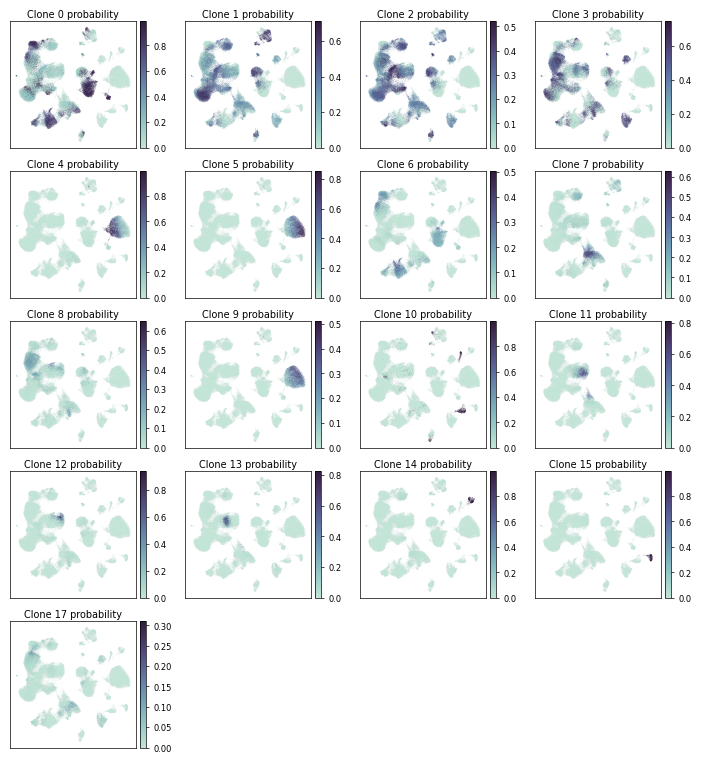

In [37]:
nk = pi.shape[1]
H = M + -(-nk // 4) * RH - GY + MB
fig, axes, letter, umap = new_figure(H)
for i in range(nk):
    umap(colx(i % 4) + LG, M + (i // 4) * RH, f'Clone {LABEL[i]} probability', cmap=PI_CMAP, vmin=0)
fig.savefig(f'{OUT}/supfig5.pdf', dpi=350)   # points at 350 dpi (G3's minimum for images): a supplementary file stays below 2 MB
fig.savefig(f'{OUT}/supfig5.png', dpi=300)
print(f'Supplementary Fig. S5: {W} x {H:.1f} pt')

### Supplementary figure after S5: the VAF of the 20 variants with $\phi \geq 0.1$, four per row

The rows of Fig. 5d in the same order, then 515A>G (not drawn in Fig. 5d, section 5); cells not covered (depth < 10) in grey. Each map gives the clones that carry the variant at $\phi \geq 0.1$ with their $\phi$ (310T>C, carried by every clone: the number of clones and the range). The maps of 709G>A, 14386T>C, 7738T>C, 12652T>C, 9554G>A (S7) and 12879T>C (Fig. 5c) are repeated on purpose: S7 pairs a clone with the variant that tells it apart, this figure shows every variant behind Fig. 5d. The colour scale runs from 0 to the largest VAF of the covered cells (the table below).

Supplementary figure of the variants: 505.69 x 538.9 pt


,covered cells,largest VAF (top of the colour scale),clones with phi >= 0.1 (phi)
12341C>T,88098,1.0,12 (0.31)
14386T>C,91959,1.0,15 (0.97)
533A>G,89945,1.0,13 (0.37)
2478G>A,91436,1.0,17 (0.14)
1415G>A,89335,1.0,17 (0.14)
146T>C,70779,1.0,10 (1.00)
709G>A,90859,1.0,"10 (1.00), 15 (0.96), 8 (0.50)"
8141G>A,91918,1.0,10 (0.76)
7738T>C,84221,1.0,"5 (1.00), 9 (0.99), 4 (0.91)"
12652T>C,80920,1.0,"5 (0.39), 9 (0.17)"


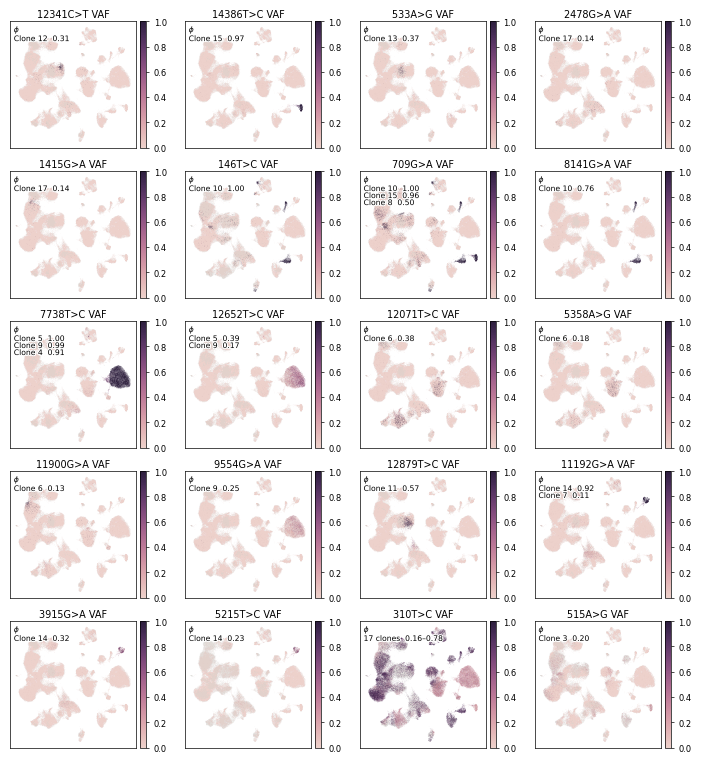

In [38]:
VARS = list(var5d['variant']) + ['515A>G']          # the rows of Fig. 5d, then 515A>G
for m in VARS:
    cells.obs[f'{m} VAF'] = np.where(D[:, col[m]] >= 10, V[:, col[m]], np.nan)    # cells not covered: no value (grey)
H = M + -(-len(VARS) // 4) * RH - GY + MB
fig, axes, letter, umap = new_figure(H)
carriers = {}
for n, m in enumerate(VARS):
    ax = umap(colx(n % 4) + LG, M + (n // 4) * RH, f'{m} VAF', cmap=VAF_CMAP, vmin=0, na_color=DIM)
    j = col[m]
    ks = np.flatnonzero(phi[j] >= 0.1)
    ks = ks[np.argsort(-phi[j, ks])]
    carriers[m] = ', '.join(f'{LABEL[i]} ({phi[j, i]:.2f})' for i in ks)
    lines = ([f'Clone {LABEL[i]}  {phi[j, i]:.2f}' for i in ks] if len(ks) <= 3
             else [f'{len(ks)} clones  {phi[j, ks].min():.2f}–{phi[j, ks].max():.2f}'])
    ax.text(0.03, 0.97, '\n'.join([r'$\phi$'] + lines), transform=ax.transAxes, va='top', ha='left', fontsize=5.5,
            path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])    # legible where cells lie under it
fig.savefig(f'{OUT}/supfig_variant_vaf.pdf')
fig.savefig(f'{OUT}/supfig_variant_vaf.png', dpi=300)
print(f'Supplementary figure of the variants: {W} x {H:.1f} pt')
pd.DataFrame({'covered cells': [int((D[:, col[m]] >= 10).sum()) for m in VARS],
              'largest VAF (top of the colour scale)': [float(V[D[:, col[m]] >= 10, col[m]].max()) for m in VARS],
              'clones with phi >= 0.1 (phi)': [carriers[m] for m in VARS]}, index=VARS)

### Supplementary Fig. S7: five clones, each beside the VAF of the variant that tells it apart (two pairs per row)

The allele frequencies $\phi$ of each clone are written below its map of $\pi$, so that they do not cover any cells.

Supplementary Fig. S7: 505.69 x 391.3 pt


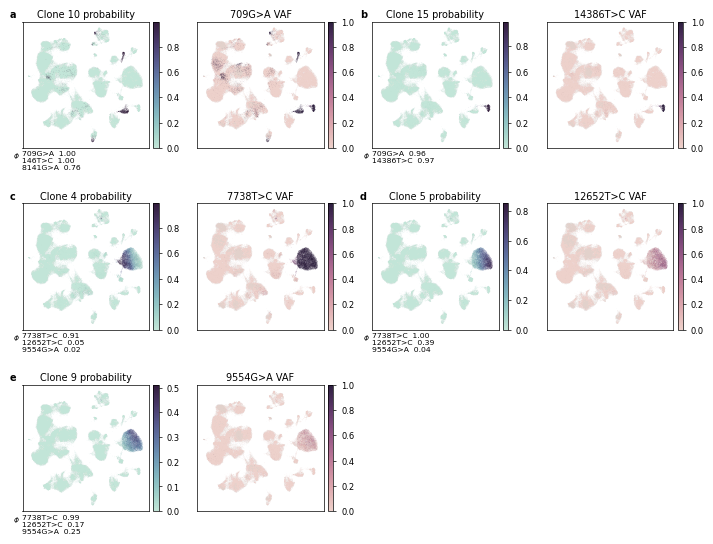

In [39]:
TB = 1.2 * 5.5 * 3 + 3                  # below each map of pi: its allele frequencies (up to three lines)
RH7 = RH + TB                           # a row of S7
H = M + 3 * RH7 - GY + MB
fig, axes, letter, umap = new_figure(H)
for n, ((k, named, m), lt) in enumerate(zip(S7, 'abcde')):
    j, r = 2 * (n % 2), n // 2
    letter(colx(j), M + r * RH7, lt)
    ax = umap(colx(j) + LG, M + r * RH7, f'Clone {k} probability', cmap=PI_CMAP, vmin=0)
    i = c_of[k]
    ax.annotate('\n'.join(f'{v}  {phi[col[v], i]:.2f}' for v in named), xy=(0, 0), xycoords='axes fraction', xytext=(0, -2),
                textcoords='offset points', va='top', ha='left', fontsize=5.5)
    ax.annotate(r'$\phi$', xy=(0, 0), xycoords='axes fraction', xytext=(-2, -2), textcoords='offset points', va='top',
                ha='right', fontsize=5.5)
    umap(colx(j + 1) + LG, M + r * RH7, f'{m} VAF', cmap=VAF_CMAP, vmin=0, na_color=DIM)
fig.savefig(f'{OUT}/supfig7.pdf', dpi=350)   # points at 350 dpi (G3's minimum for images): a supplementary file stays below 2 MB
fig.savefig(f'{OUT}/supfig7.png', dpi=300)
print(f'Supplementary Fig. S7: {W} x {H:.1f} pt')

### Supplementary Fig. S6: the decomposition of the allele frequency

Square cells of 8 pt, so that the 64 variants fit on a page; the heatmaps are centred in the text width.

Supplementary Fig. S6: 505.69 x 571.0 pt; the heatmaps 354.0 pt wide


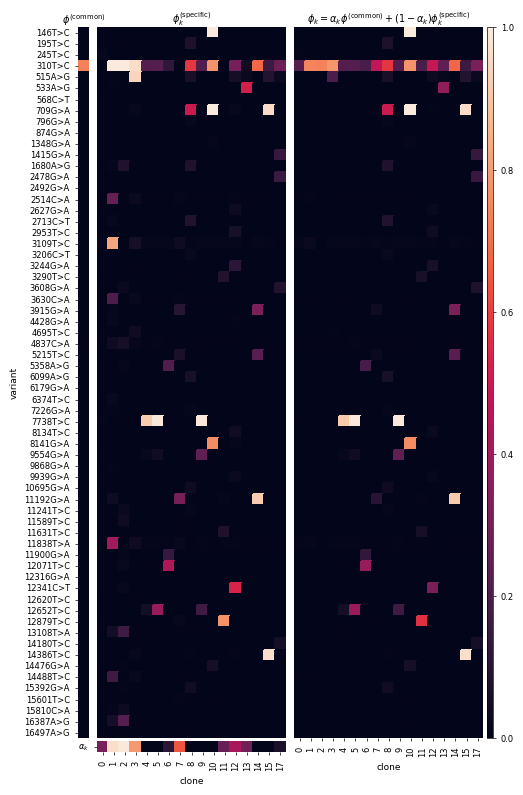

In [40]:
labels_k = [str(LABEL[i]) for i in range(nk)]
nv = len(variants)
LV = 36                                              # variant names
G6 = 6                                               # gap between the heatmaps
B6 = 30                                              # below: clone numbers and 'clone'
c6 = 8                                               # cell: the figure (64 rows) fits on a page
T6 = T + 3                                           # title row: the superscripts of the titles need 3 pt more
H = M + T6 + nv * c6 + 2 + c6 + B6 + MB              # the row of alpha below phi_specific
blockw = LV + c6 + G6 + nk * c6 + G6 + nk * c6 + CB_ROOM
x0 = (W - blockw) / 2                                # the block centred in the text width
fig, axes, letter, umap = new_figure(H)
kw = dict(vmin=0, vmax=1, cbar=False, linewidths=0.3, linecolor='face')
y = M + T6
ax0 = axes(x0 + LV, y, c6, nv * c6)
sns.heatmap(phi0[:, None], ax=ax0, yticklabels=list(variants), xticklabels=False, **kw)
ax0.set_title(r'$\phi^{(\mathrm{common})}$')
ax0.set_ylabel('variant')
x1 = x0 + LV + c6 + G6
ax1 = axes(x1, y, nk * c6, nv * c6)
sns.heatmap(phik, ax=ax1, yticklabels=False, xticklabels=False, **kw)
ax1.set_title(r'$\phi^{(\mathrm{specific})}_k$')
axa = axes(x1, y + nv * c6 + 2, nk * c6, c6)
sns.heatmap(alpha[kept][None, :], ax=axa, yticklabels=[r'$\alpha_k$'], xticklabels=labels_k, **kw)
axa.set_xlabel('clone')
x2 = x1 + nk * c6 + G6
ax2 = axes(x2, y, nk * c6, nv * c6)
sns.heatmap(phi, ax=ax2, yticklabels=False, xticklabels=labels_k, **kw)
ax2.set_title(r'$\phi_k = \alpha_k \phi^{(\mathrm{common})} + (1 - \alpha_k) \phi^{(\mathrm{specific})}_k$')
ax2.set_xlabel('clone')
for a in (axa, ax2):
    a.tick_params(axis='x', rotation=90)
axa.tick_params(axis='y', rotation=0)
fig.colorbar(ax2.collections[0], cax=axes(x2 + nk * c6 + CB_PAD, y, CB_W, nv * c6))
fig.savefig(f'{OUT}/supfig6.pdf')
fig.savefig(f'{OUT}/supfig6.png', dpi=300)
print(f'Supplementary Fig. S6: {W} x {H:.1f} pt; the heatmaps {blockw:.1f} pt wide')